# Phase 2 — Neural extraction to reviewed Bayesian reasoning

Team T094 / Section E. This executed notebook reconstructs reported held-out metrics, runs the released neural model, validates the controlled teaching DAG and answers interventions. Full training commands are recorded below; they do not execute automatically. Entity spans are supplied. The synthetic graph is a case study, not a real-world causal discovery benchmark.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT/'src').is_dir(): raise RuntimeError('Start from the repository or notebooks directory')
sys.path.insert(0,str(ROOT))
import pandas as pd
from scripts.verify_final_results import verify
report = json.loads((ROOT/'artifacts/phase2/final_evaluation/metrics.json').read_text())
verify(ROOT/'artifacts/phase2/final_evaluation')

/Users/Mystic/Documents/Codex/2026-11-01/th/work/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/Mystic/Documents/Codex/2026-11-01/th/work/venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


{'status': 'PASS',
 'test_rows': 2700,
 'models_reconstructed': 10,
 'checks': ['available hashes',
  'test alignment',
  'all directed metrics',
  'seed statistics',
  'graph acceptance',
  'known intervention oracles'],
 'scope': 'Numeric artifact audit; full neural prediction reproduction requires the released model or local checkpoints'}

## 1. Data and a fair comparison
Source is pinned SemEval Task 8, reduced to no-causal / e1→e2 / e2→e1. Entity names are masked. Identical sentence-group partitions and masking are shared by ML and DL. There are no missing sentence/label values, no removed exact-pair duplicates, and 17/2,717 test rows removed for sentence overlap. Source document IDs are unavailable; sentence groups are the attainable grouping unit.

In [2]:
audit=json.loads((ROOT/'artifacts/phase2/data_audit.json').read_text())
{'raw_checks':audit['raw_checks'],'test_overlap_removed':audit['test_sentence_overlap_removed'],'pairwise_group_overlap':audit['pairwise_group_overlap']}

{'raw_checks': {'train': {'raw_rows': 8000,
   'missing_sentence': 0,
   'missing_relation': 0,
   'duplicate_pairs_removed': 0},
  'test': {'raw_rows': 2717,
   'missing_sentence': 0,
   'missing_relation': 0,
   'duplicate_pairs_removed': 0}},
 'test_overlap_removed': 17,
 'pairwise_group_overlap': {'train_dev': 0, 'train_test': 0, 'dev_test': 0}}

## 2. Held-out extraction, ablations and stability
The weighted seed-42 primary was declared before held-out testing. Development edge F1 selects checkpoints. The unweighted ablation does better in this run; it is reported without test-based reselection. The frozen encoder uses the same budget and is not separately tuned. Accuracy, macro F1 and edge F1 measure different things.

In [3]:
pd.DataFrame(report['test']).T[['edge_precision','edge_recall','edge_f1','macro_f1']].round(6)

,edge_precision,edge_recall,edge_f1,macro_f1
majority,0.0,0.0,0.0,0.311847
lexical,0.847059,0.66055,0.742268,0.821555
tfidf_lr,0.819572,0.819572,0.819572,0.875658
entity_only_ablation,0.532423,0.477064,0.503226,0.644063
fine_tuned_weighted_seed42,0.857567,0.883792,0.870482,0.910059
fine_tuned_weighted_seed17,0.860947,0.889908,0.875188,0.91211
fine_tuned_weighted_seed2026,0.851744,0.896024,0.873323,0.913388
frozen_encoder_weighted_seed42,0.289617,0.324159,0.305916,0.437952
fine_tuned_unweighted_seed42,0.901538,0.896024,0.898773,0.928829
deployed_int8,0.854167,0.877676,0.865762,0.905282


In [4]:
{'primary_95ci':report['primary_edge_f1_bootstrap_95ci'],'paired_gain':report['primary_minus_ml_edge_f1'],'seed_stability':report['seed_stability']}

{'primary_95ci': [0.8421012637977923, 0.8973670789238811],
 'paired_gain': 0.05091006226741834,
 'seed_stability': {'seeds': [42, 17, 2026],
  'edge_f1': [0.8704819277108434, 0.875187969924812, 0.8733233979135618],
  'mean': 0.8729977651830724,
  'sample_sd': 0.002369859876931115}}

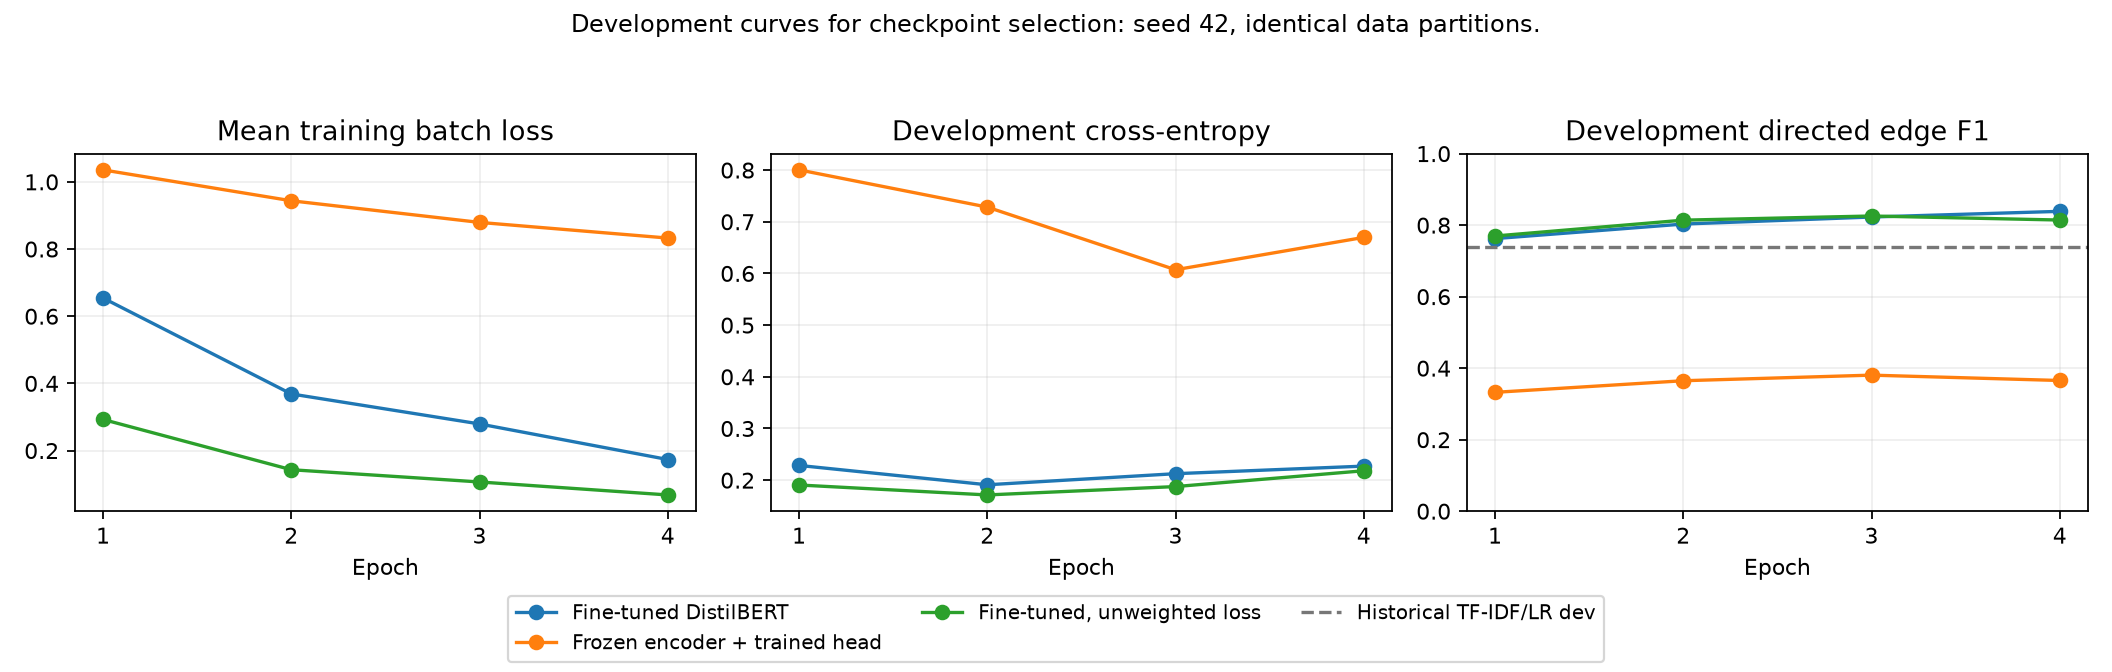

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'artifacts/phase2/development/final_20261123/learning_curves.png')))

## 3. Run the actual deployed neural classifier
The SHA-256-pinned public release downloads once if absent. This is the quantized primary checkpoint, evaluated separately at edge F1 0.866. Scores are uncalibrated and are not causal probabilities. No API key, PyTorch or Transformers is needed for inference.

In [6]:
from src.neural_runtime import OnnxExtractor, ensure_bundle
manifest=json.loads((ROOT/'artifacts/neural/release.json').read_text())
model=OnnxExtractor(ensure_bundle(manifest))
texts=['<e1>Heat</e1> causes <e2>evaporation</e2>.','<e1>Flooding</e1> is caused by <e2>rain</e2>.','The <e1>water</e1> is in the <e2>glass</e2>.']
prob=model.predict_proba(texts)
pd.DataFrame(prob,columns=['no relation','e1 causes e2','e2 causes e1']).assign(predicted_label=prob.argmax(axis=1))

,no relation,e1 causes e2,e2 causes e1,predicted_label
0,0.000291,0.999569,0.000140,1
1,0.001113,0.000320,0.998567,2
2,0.999500,0.000240,0.000260,0


## 4. Neural candidates, documented review and DAG constraints
The last deliberately conflicting sentence still expresses causal wording, so the language model may accept it confidently. This controlled example uses a scripted known-generator reviewer. For real usage the app requires explicit user review; graph checks are not proof of causal truth. Processing order can affect which cycle-closing edge is rejected.

In [7]:
from src.hybrid import candidate_record
from src.causal import build_graph, observations, query, oracle
texts=['<e1>Rain</e1> causes <e2>sprinkler</e2>.','<e1>Rain</e1> causes <e2>wet grass</e2>.','<e1>Sprinkler</e1> causes <e2>wet grass</e2>.','<e1>Wet grass</e1> causes <e2>rain</e2>.']
probs=model.predict_proba(texts)
candidates=[candidate_record(t,int(p.argmax()),p,'notebook_teaching_case',i+1) for i,(t,p) in enumerate(zip(texts,probs))]
candidates=[x for x in candidates if x]
graph,accepted,rejected=build_graph(candidates)
print('Kept:',len(accepted),'Rejected:',len(rejected))
pd.DataFrame(rejected)[['cause','effect','reason']]

Kept: 3 Rejected: 1


,cause,effect,reason
0,wet_grass,rain,would create a cycle


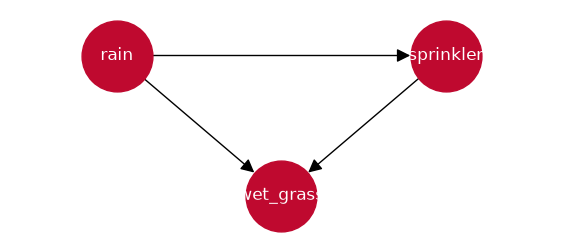

In [8]:
import networkx as nx
import matplotlib.pyplot as plt
assert set(graph.edges())=={('rain','sprinkler'),('rain','wet_grass'),('sprinkler','wet_grass')}
assert nx.is_directed_acyclic_graph(graph)
fig,ax=plt.subplots(figsize=(7,3))
nx.draw_networkx(graph,{'rain':(0,1),'sprinkler':(1,1),'wet_grass':(.5,0)},ax=ax,node_size=2600,node_color='#BF092F',font_color='white',arrowsize=20)
ax.margins(.25);ax.axis('off');plt.show()

## 5. Fit CPDs from matching observations and query do()
6,000 seeded binary observations estimate CPDs with a BDeu prior, equivalent sample size 5. The DAG must be causally justified, rain must account for the shared cause, and other mechanisms must remain stable. Neural scores never become CPDs. do(sprinkler=1) removes rain→sprinkler and fixes the sprinkler while rain can still affect wet grass. These are population interventions, not individual counterfactuals.

In [9]:
from src.reviewed_network import fit_reviewed_network
network,audit=fit_reviewed_network([dict(x,approved=True) for x in accepted],observations(),{'reviewed_by':'Scripted known-generator reviewer','causal_rationale':'Controlled synthetic generator; this review is not independent real-world annotation','observed_confounders':True,'stable_mechanisms':True})
results=pd.DataFrame([{'sprinkler':v,'observed':query(variable='sprinkler',value=v,network=network),'intervened':query(variable='sprinkler',value=v,intervention=True,network=network),'known_generator':oracle(v)} for v in [0,1]])
assert max(abs(results.intervened-results.known_generator))<.011
results.round(6)

,sprinkler,observed,intervened,known_generator
0,0,0.452367,0.274770,0.284
1,1,0.801081,0.846489,0.857


In [10]:
for cpd in network.get_cpds(): print(cpd)

+---------+----------+
| rain(0) | 0.707327 |
+---------+----------+
| rain(1) | 0.292673 |
+---------+----------+
+--------------+--------------------+----------------------+
| rain         | rain(0)            | rain(1)              |
+--------------+--------------------+----------------------+
| sprinkler(0) | 0.4005297233666863 | 0.9492176386913229   |
+--------------+--------------------+----------------------+
| sprinkler(1) | 0.5994702766333138 | 0.050782361308677096 |
+--------------+--------------------+----------------------+
+--------------+-----+----------------------+
| rain         | ... | rain(1)              |
+--------------+-----+----------------------+
| sprinkler    | ... | sprinkler(1)         |
+--------------+-----+----------------------+
| wet_grass(0) | ... | 0.029411764705882353 |
+--------------+-----+----------------------+
| wet_grass(1) | ... | 0.9705882352941176   |
+--------------+-----+----------------------+


## Full training reproduction (run separately)
Install `requirements-dl.txt`, run `python -m scripts.prepare_neural_data`, then `python -m scripts.train_neural --variant fine_tuned_weighted --seed 42 --output artifacts/phase2/runs/repro_primary`. Repeat for weighted seeds 17/2026, `frozen_encoder_weighted` seed42 and `fine_tuned_unweighted` seed42. Each run uses four epochs, batch16, AdamW 2e-5, dropout0.2, weight decay0.01, clipping1. Export the primary with `scripts.export_neural_onnx --run PATH --output FRESH_PATH`; evaluate all five with `scripts.evaluate_neural_final --runs ... --onnx BUNDLE --output FRESH_PATH`. See docs/phase2.md and stored training_records.json for full provenance.

References: [DistilBERT](https://arxiv.org/abs/1910.01108), [SemEval Task8](https://aclanthology.org/S10-1006/), [Pearl](https://bayes.cs.ucla.edu/BOOK-2K/), [pgmpy](https://jmlr.org/papers/v25/23-0487.html).